# Lab: Relationships Between Quantitative Features

Use a historical mammal sleep dataset to compare dreaming, non-dreaming, and total sleep. Use non-dreaming versus total sleep as the main model, then examine whether danger and predation ratings add information. Finally, investigate the nonlinear pattern between gestation time and total sleep.

Support conclusions with the plots and calculations. Explain how well a straight line follows the points and how much variation remains.

## Learning goals

- Describe whether points trend upward or downward, follow a straight or curved pattern, cluster closely around that pattern, or include unusual observations.
- Calculate correlation and interpret R-squared on the correct response scale.
- Recognize nonlinear patterns and compare original gestation with log-transformed gestation.
- Examine additional categorical features visually and compare model R-squared on the same observations.
- Check missing codes, units, category counts, and transformations.
- Distinguish improved fit to observed records from causation and performance on new data.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete each investigation in order. Use separate cells for individual operations and add cells as needed. Give figures informative titles, named colors, and axis labels with units or transformations. Use the default point transparency and line widths. `ci=None` can omit confidence bands so the patterns and group lines are easier to compare.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code and checking every claim against the source and your output. Complete the AI-use reflection at the end.

## Dataset and context

Use the [StatLib mammal sleep data hosted by UC Berkeley](https://www.stat.berkeley.edu/~spector/s100/data/sleep.dat) and its [measurement dictionary](https://www.stat.berkeley.edu/~spector/s100/data/sleep.html). A local copy is supplied as `data/mammal_sleep.csv`.

The supplied `data/mammal_sleep.csv` contains all 62 records and 11 features, including species names and both sleep phases. One row describes a mammal species, not an individual animal or a night. The data trace to Allison and Cicchetti's 1976 study, [Sleep in mammals: ecological and constitutional correlates](https://pubmed.ncbi.nlm.nih.gov/982039/). This is a historical comparative dataset, not a random sample of all mammals; individual collection dates are not supplied.

Course preparation preserves all values and names, gives columns descriptive names, and converts the source's `-999` missing code into blank CSV fields. Use ordinary `pd.read_csv()`; blanks are recognized as missing. The terms dreaming and non-dreaming identify the study's sleep-phase measurements; they are not direct reports of an animal's subjective dream experiences.

### Data dictionary

| Feature | Meaning and units or codes |
| --- | --- |
| `species` | Species label as recorded in the historical source |
| `non_dreaming_sleep` | Non-dreaming sleep in hours per day |
| `dreaming_sleep` | Dreaming sleep in hours per day |
| `body_weight` | Body weight in kilograms |
| `brain_weight` | Brain weight in grams |
| `max_life_span` | Maximum lifespan in years |
| `gestation_time` | Gestation duration in days |
| `predation_index` | Ordered rating, 1–5: lower to higher likelihood of being preyed upon |
| `sleep_exposure_index` | Ordered rating, 1–5: more protected to more exposed sleeping conditions |
| `danger_index` | Ordered rating, 1–5: lower to higher overall danger from other animals |
| `total_sleep` | Total sleep in hours per day; sum of the two phases |

The indices are **ordinal categorical features**, even though stored as numbers. A one-point difference is not a documented equal increment of physical risk. Overall danger incorporates predation, sleep exposure, and other information, so these ratings are not independent measurements. In our models, represent rating levels as categories rather than assuming equal numerical spacing.

## Load and inspect the data

In [1]:
# Import NumPy, Pandas, Matplotlib pyplot, and Seaborn.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Read data/mammal_sleep.csv into mammals_df; blank fields are recognized as missing.
mammals_df = pd.read_csv("data/mammal_sleep.csv")


In [3]:
# Display the first five rows.
mammals_df.head()


,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4


In [4]:
# Display the last five rows.
mammals_df.tail()


,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1
61,Yellow-bellied marmot,4.050,17.0,NaN,NaN,NaN,13.0,38.0,3,1,1


In [5]:
# Display the shape.
mammals_df.shape


(62, 11)

In [6]:
# Use .info() to inspect the data storage types and non-missing values.
mammals_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     object 
 1   body_weight           62 non-null     float64
 2   brain_weight          62 non-null     float64
 3   non_dreaming_sleep    48 non-null     float64
 4   dreaming_sleep        50 non-null     float64
 5   total_sleep           58 non-null     float64
 6   max_life_span         58 non-null     float64
 7   gestation_time        58 non-null     float64
 8   predation_index       62 non-null     int64  
 9   sleep_exposure_index  62 non-null     int64  
 10  danger_index          62 non-null     int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 5.5+ KB


In [7]:
# Count missing values in every feature.
mammals_df.isnull().sum()


species                  0
body_weight              0
brain_weight             0
non_dreaming_sleep      14
dreaming_sleep          12
total_sleep              4
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
dtype: int64

**What does one row represent?**

Your answer:

One row is one mammal species. The file has 62 species, and each row holds that species' recorded sleep, body, lifespan, gestation, and risk-rating values. It is not one animal or one night of sleep.


**Complete the table using the data dictionary, `.info()`, and `.isnull().sum()`. For data type, use categorical or quantitative. For data storage type, report the Pandas dtype. For missing values, report the count, including 0 when none are missing.**

| Feature | Data type | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `species` | categorical | object | 0 |
| `non_dreaming_sleep` | quantitative | float64 | 14 |
| `dreaming_sleep` | quantitative | float64 | 12 |
| `body_weight` | quantitative | float64 | 0 |
| `brain_weight` | quantitative | float64 | 0 |
| `max_life_span` | quantitative | float64 | 4 |
| `gestation_time` | quantitative | float64 | 4 |
| `predation_index` | categorical | int64 | 0 |
| `sleep_exposure_index` | categorical | int64 | 0 |
| `danger_index` | categorical | int64 | 0 |
| `total_sleep` | quantitative | float64 | 4 |

Your answer:

The three index features are stored as int64, but the data dictionary says they are ordered ratings from 1 to 5, so I list them as categorical. `species` is a text label that is different on every row. The two sleep-phase features have the most missing values (14 and 12). `species`, `body_weight`, `brain_weight`, and the three indices have none missing.


# Investigation 1: Dreaming, non-dreaming, and total sleep

## Step 1: Question

**How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?**

Compare three relationships in hours per day: dreaming versus non-dreaming, dreaming versus total, and non-dreaming versus total. In the last comparison, use non-dreaming sleep on the horizontal axis and total sleep as the response. This is the main model for Investigation 2.

**Predict the direction and strength of each relationship. Which phase do you expect to be more strongly related to total sleep, and why?**

Your answer:

I expect all three relationships to be positive. Dreaming and non-dreaming sleep should rise together, but loosely, because a species that sleeps more has room for more of both phases while the split between them can still differ. Both phases should rise with total sleep because total sleep is the two added together. I expect non-dreaming sleep to be the more strongly related one, since I think it makes up most of a mammal's sleep and so should drive most of the differences in the total.


## Step 2: Data

Create `sleep_df` from records complete for `dreaming_sleep`, `non_dreaming_sleep`, `total_sleep`, `danger_index`, and `predation_index`. Use `.copy()` and keep `mammals_df` unchanged. Use this same subset in all three comparisons and in Investigation 2. How many records were removed from the dataset?

Check that sleep measurements are between 0 and 24 hours per day.

In [8]:
# Prepare sleep_df and check sample size and sleep ranges.
sleep_features = ["dreaming_sleep", "non_dreaming_sleep", "total_sleep", "danger_index", "predation_index"]
sleep_df = mammals_df.dropna(subset=sleep_features).copy()

print("Records in mammals_df:", len(mammals_df))
print("Records in sleep_df:", len(sleep_df))
print("Records removed:", len(mammals_df) - len(sleep_df))

sleep_df[["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]].agg(["min", "max"])


Records in mammals_df: 62
Records in sleep_df: 48
Records removed: 14


,dreaming_sleep,non_dreaming_sleep,total_sleep
min,0.0,2.1,2.9
max,6.6,17.9,19.9


In [9]:
# Display the removed records to see which measurements they are missing.
removed_from_sleep = mammals_df.loc[~mammals_df.index.isin(sleep_df.index), ["species", *sleep_features]]
print("Removed records with no total sleep value:", removed_from_sleep["total_sleep"].isnull().sum())
print("Removed records that have total sleep but lack a sleep phase:", removed_from_sleep["total_sleep"].notnull().sum())
removed_from_sleep


Removed records with no total sleep value: 4
Removed records that have total sleep but lack a sleep phase: 10


,species,dreaming_sleep,non_dreaming_sleep,total_sleep,danger_index,predation_index
0,African elephant,NaN,NaN,3.3,3,3
2,Arctic Fox,NaN,NaN,12.5,1,1
3,Arctic ground squirrel,NaN,NaN,16.5,3,5
13,Donkey,NaN,NaN,3.1,5,5
20,Giraffe,0.3,NaN,NaN,5,5
23,Gorilla,NaN,NaN,12.0,1,1
25,Gray wolf,NaN,NaN,13.0,1,1
29,Jaguar,NaN,NaN,10.8,1,1
30,Kangaroo,NaN,NaN,NaN,4,3
40,Okapi,1.0,NaN,NaN,5,5


## Step 3: Evidence

Create three labeled regression plots with `sns.regplot()`: non-dreaming sleep versus dreaming sleep, total sleep versus dreaming sleep, and total sleep versus non-dreaming sleep. In each description, the feature after “versus” goes on the horizontal axis. Calculate the correlation and simple-line R-squared for each pair. Describe the points before relying on the fitted line.

When describing a scatterplot:

- **Direction:** Do the points generally rise or fall from left to right?
- **Form:** Does the overall pattern look roughly straight, curved, or have no clear shape? This describes the arrangement of the points, not the line drawn by the plotting function.
- **Strength:** How closely do the points follow that pattern?
- **Unusual observations:** Which points are far from most of the others?

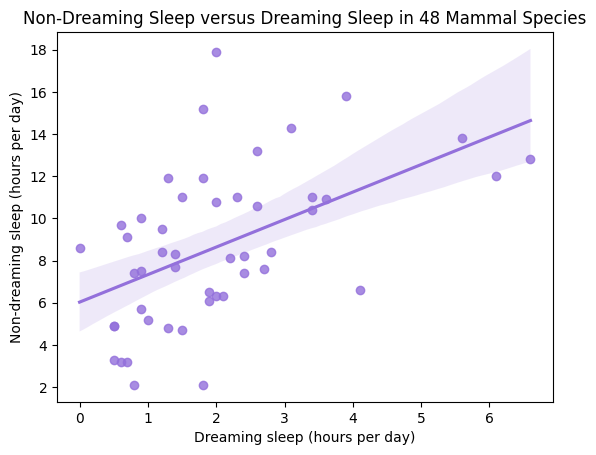

In [10]:
# Plot dreaming sleep and non-dreaming sleep.
sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="non_dreaming_sleep",
    color="mediumpurple"
)
plt.title("Non-Dreaming Sleep versus Dreaming Sleep in 48 Mammal Species")
plt.xlabel("Dreaming sleep (hours per day)")
plt.ylabel("Non-dreaming sleep (hours per day)")
plt.show()


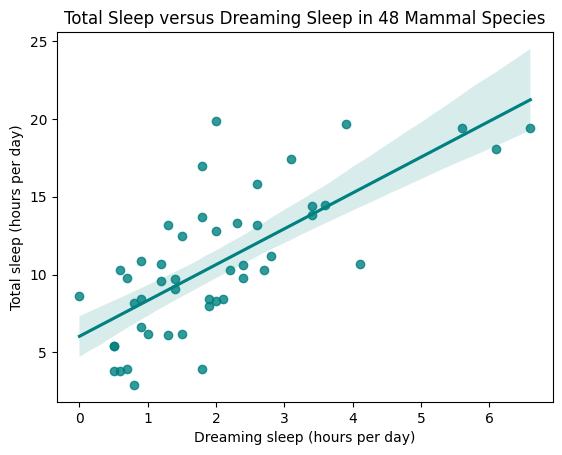

In [11]:
# Plot dreaming sleep and total sleep.
sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="total_sleep",
    color="teal"
)
plt.title("Total Sleep versus Dreaming Sleep in 48 Mammal Species")
plt.xlabel("Dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.show()


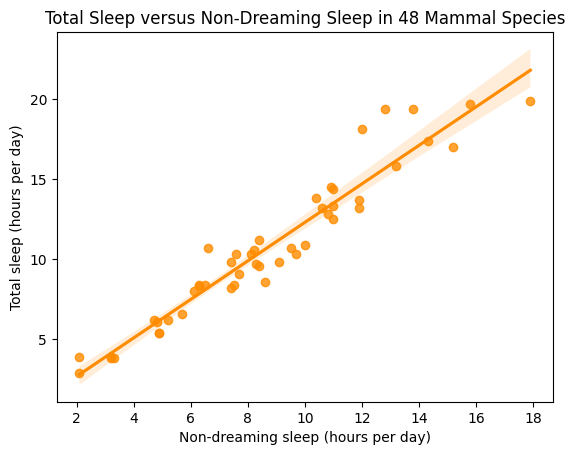

In [12]:
# Plot non-dreaming sleep and total sleep.
sns.regplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    color="darkorange"
)
plt.title("Total Sleep versus Non-Dreaming Sleep in 48 Mammal Species")
plt.xlabel("Non-dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.show()


In [13]:
# Calculate all three correlations and R-squared values.
sleep_correlations = sleep_df[["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]].corr()
display(sleep_correlations.round(3))

# For a simple line with an intercept, R-squared is the squared correlation.
sleep_r_squared = sleep_correlations ** 2
display(sleep_r_squared.round(3))


,dreaming_sleep,non_dreaming_sleep,total_sleep
dreaming_sleep,1.000,0.514,0.727
non_dreaming_sleep,0.514,1.000,0.963
total_sleep,0.727,0.963,1.000


,dreaming_sleep,non_dreaming_sleep,total_sleep
dreaming_sleep,1.000,0.264,0.529
non_dreaming_sleep,0.264,1.000,0.927
total_sleep,0.529,0.927,1.000


In [14]:
# Display the records that sit farthest from the other points in the three plots.
unusual_cols = ["species", "dreaming_sleep", "non_dreaming_sleep", "total_sleep"]

print("Three longest dreaming-sleep records:")
display(sleep_df.nlargest(3, "dreaming_sleep")[unusual_cols])

print("Record with the fourth-longest dreaming sleep, for comparison:")
display(sleep_df.nlargest(4, "dreaming_sleep")[unusual_cols].tail(1))

print("Three shortest total-sleep records:")
display(sleep_df.nsmallest(3, "total_sleep")[unusual_cols])


Three longest dreaming-sleep records:


,species,dreaming_sleep,non_dreaming_sleep,total_sleep
60,Water opossum,6.6,12.8,19.4
19,Giant armadillo,6.1,12.0,18.1
38,N. American opossum,5.6,13.8,19.4


Record with the fourth-longest dreaming sleep, for comparison:


,species,dreaming_sleep,non_dreaming_sleep,total_sleep
16,European hedgehog,4.1,6.6,10.7


Three shortest total-sleep records:


,species,dreaming_sleep,non_dreaming_sleep,total_sleep
28,Horse,0.8,2.1,2.9
21,Goat,0.5,3.3,3.8
53,Sheep,0.6,3.2,3.8


In [15]:
# Express the non-dreaming and dreaming R-squared values as percentages of total-sleep variation.
non_dreaming_r_squared = sleep_r_squared.loc["non_dreaming_sleep", "total_sleep"]
dreaming_r_squared = sleep_r_squared.loc["dreaming_sleep", "total_sleep"]

print(f"Non-dreaming sleep accounts for {non_dreaming_r_squared * 100:.1f}% of the variation in total sleep")
print(f"Left unaccounted for by that line: {(1 - non_dreaming_r_squared) * 100:.1f}%")
print(f"Dreaming sleep accounts for {dreaming_r_squared * 100:.1f}% of the variation in total sleep")

# Average share of total sleep spent in each phase.
print(f"Mean non-dreaming sleep: {sleep_df['non_dreaming_sleep'].mean():.2f} hours per day")
print(f"Mean dreaming sleep: {sleep_df['dreaming_sleep'].mean():.2f} hours per day")
print(f"Mean total sleep: {sleep_df['total_sleep'].mean():.2f} hours per day")
print(f"Non-dreaming share of mean total sleep: {sleep_df['non_dreaming_sleep'].mean() / sleep_df['total_sleep'].mean() * 100:.1f}%")


Non-dreaming sleep accounts for 92.7% of the variation in total sleep
Left unaccounted for by that line: 7.3%
Dreaming sleep accounts for 52.9% of the variation in total sleep
Mean non-dreaming sleep: 8.67 hours per day
Mean dreaming sleep: 2.03 hours per day
Mean total sleep: 10.70 hours per day
Non-dreaming share of mean total sleep: 81.1%


In [16]:
# Find the species farthest above and below the line in the non-dreaming versus total sleep plot.
line_slope, line_intercept = np.polyfit(sleep_df["non_dreaming_sleep"], sleep_df["total_sleep"], 1)
line_check = sleep_df[["species", "non_dreaming_sleep", "dreaming_sleep", "total_sleep"]].copy()
line_check["hours_above_line"] = line_check["total_sleep"] - (line_intercept + line_slope * line_check["non_dreaming_sleep"])

print("Three species farthest above the line:")
display(line_check.nlargest(3, "hours_above_line").round(2))

print("Three species farthest below the line:")
display(line_check.nsmallest(3, "hours_above_line").round(2))


Three species farthest above the line:


,species,non_dreaming_sleep,dreaming_sleep,total_sleep,hours_above_line
60,Water opossum,12.8,6.6,19.4,3.74
19,Giant armadillo,12.0,6.1,18.1,3.40
38,N. American opossum,13.8,5.6,19.4,2.53


Three species farthest below the line:


,species,non_dreaming_sleep,dreaming_sleep,total_sleep,hours_above_line
15,Echidna,8.6,0.0,8.6,-2.01
32,Little brown bat,17.9,2.0,19.9,-1.90
59,Vervet,9.7,0.6,10.3,-1.64


**For each plot, do the points generally rise or fall? Is their pattern roughly straight or curved, and how closely do they follow it? Identify any unusual observations. Which plot is best summarized by a straight line? Explain what its R-squared tells you about total sleep.**

Your answer:

**Non-dreaming versus dreaming sleep.** The points rise from left to right, but loosely. The pattern is roughly straight with a wide spread around it, and the correlation is 0.514 (R-squared 0.264). Three species sit far to the right of all the others: the water opossum (6.6 hours of dreaming sleep), the giant armadillo (6.1), and the North American opossum (5.6). The next longest is the European hedgehog at 4.1. The highest point belongs to the little brown bat, with 17.9 hours of non-dreaming sleep and 2.0 hours of dreaming sleep.

**Total versus dreaming sleep.** The points rise and follow a rough straight pattern more closely than in the first plot. The correlation is 0.727 (R-squared 0.529). The same three long-dreaming species are alone at the far right, so the right end of the line rests on them.

**Total versus non-dreaming sleep.** The points rise in a tight, straight band. The correlation is 0.963 (R-squared 0.927). The species farthest above the line are the same three long dreamers, the water opossum (3.74 hours above), the giant armadillo (3.40), and the North American opossum (2.53). The species farthest below it is the echidna (2.01 hours below), which has 0.0 hours of dreaming sleep recorded.

The third plot is the one best summarized by a straight line. Its R-squared says that a line in non-dreaming sleep accounts for 92.7% of the variation in total sleep across these 48 species, which leaves 7.3% that the line does not account for.


## Step 4: Check

Check that `dreaming_sleep + non_dreaming_sleep` agrees with `total_sleep` using `np.isclose()`, which allows for ordinary floating-point rounding. Display several original rows with their phase sum. Then display the three records with the longest non-dreaming sleep and locate their points on the non-dreaming versus total sleep plot. Do the plotted values agree with the records?

In [17]:
# Check the sleep-phase sum and display original measurements.
sleep_df["phase_sum"] = sleep_df["dreaming_sleep"] + sleep_df["non_dreaming_sleep"]
sleep_df["sum_matches_total"] = np.isclose(sleep_df["phase_sum"], sleep_df["total_sleep"])

print("Records where the phase sum agrees with total sleep:", sleep_df["sum_matches_total"].sum(), "of", len(sleep_df))

sleep_df[["species", "dreaming_sleep", "non_dreaming_sleep", "phase_sum", "total_sleep", "sum_matches_total"]].head(8)


Records where the phase sum agrees with total sleep: 48 of 48


,species,dreaming_sleep,non_dreaming_sleep,phase_sum,total_sleep,sum_matches_total
1,African giant pouched rat,2.0,6.3,8.3,8.3,True
4,Asian elephant,1.8,2.1,3.9,3.9,True
5,Baboon,0.7,9.1,9.8,9.8,True
6,Big brown bat,3.9,15.8,19.7,19.7,True
7,Brazilian tapir,1.0,5.2,6.2,6.2,True
8,Cat,3.6,10.9,14.5,14.5,True
9,Chimpanzee,1.4,8.3,9.7,9.7,True
10,Chinchilla,1.5,11.0,12.5,12.5,True


In [18]:
# Inspect the three records with the longest non-dreaming sleep.
sleep_df.nlargest(3, "non_dreaming_sleep")[["species", "non_dreaming_sleep", "dreaming_sleep", "total_sleep"]]


,species,non_dreaming_sleep,dreaming_sleep,total_sleep
32,Little brown bat,17.9,2.0,19.9
6,Big brown bat,15.8,3.9,19.7
41,Owl monkey,15.2,1.8,17.0


## Step 5: Conclusion

**Research question:** How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?

**Do mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep? Which phase is more strongly related to total sleep? Support your answers with the plots, correlations, and R-squared values. Did the results match your prediction?**

Your answer:

Yes, but only loosely. The first plot rises with a lot of scatter, the correlation between the two phases is 0.514, and its R-squared is 0.264, so most of the variation in one phase is not accounted for by the other.

Non-dreaming sleep is much more strongly related to total sleep than dreaming sleep is. Its correlation with total sleep is 0.963 against 0.727 for dreaming sleep, and its R-squared is 0.927 against 0.529. The plots agree with the numbers. The non-dreaming plot is a tight band and the dreaming plot is a loose cloud whose right end depends on three species.

The results match my prediction on direction and on which phase is stronger. The reason I gave also holds up in the data: non-dreaming sleep averages 8.67 of the 10.70 hours of total sleep, which is 81.1%.


## Step 6: Limitation

**State two limitations specific to these sleep relationships. Explain why a stronger correlation is not automatically a better scientific explanation.**

Your answer:

1. Total sleep is not a separate measurement from the two phases. The check shows that dreaming plus non-dreaming sleep equals total sleep in 48 of 48 records. Each phase is a part of the response it is being compared with, so a positive relationship is guaranteed, and the larger part will have the larger correlation. The 0.963 mostly reflects that non-dreaming sleep is 81.1% of the total.

2. The comparison uses 48 of the 62 species. Fourteen were removed for missing sleep-phase values, and 10 of those have a total sleep value that is left out here. The species are a historical collection, not a random sample of mammals, and each row is one recorded value per species, so differences between individual animals are not in the data.

A stronger correlation is not automatically a better scientific explanation because correlation only measures how closely the points follow a line. Here the strongest correlation comes from arithmetic, since one feature is most of the other. It does not say why some species sleep more than others.


# Investigation 2: Do danger and predation add information?

## Step 1: Question

**Do danger and predation categories add information about total sleep beyond non-dreaming sleep?**

**Predict whether each index will add substantial, small, or little visible information. What would you look for at comparable non-dreaming-sleep durations?**

Your answer:

I expect both indices to add little visible information. Non-dreaming sleep already accounts for 92.7% of the variation in total sleep, so there is not much left for anything else to account for. If danger matters, I would look for species with high danger ratings sitting lower on the plot than low-danger species that have about the same non-dreaming sleep. I expect danger to add slightly more than predation, because the data dictionary says overall danger takes in predation and sleep exposure together.


## Step 2: Data

Reuse `sleep_df` and its original sleep measurements. Count records for each danger and predation rating and display a cross-tabulation of the two indices. Keep all five original levels in their natural order. Higher predation index values mean a mammal is more likely to be preyed upon. Higher danger index values mean greater overall danger from other animals.

In [19]:
# Count the records at each danger and predation level.
rating_counts = pd.DataFrame({
    "danger_index": sleep_df["danger_index"].value_counts().sort_index(),
    "predation_index": sleep_df["predation_index"].value_counts().sort_index()
})
rating_counts.index.name = "rating"
rating_counts


,danger_index,predation_index
rating,,
1,14,10
2,12,13
3,8,9
4,9,7
5,5,9


In [20]:
# Cross-tabulate danger and predation ratings.
pd.crosstab(sleep_df["danger_index"], sleep_df["predation_index"])


predation_index,1,2,3,4,5
danger_index,,,,,
1,10,4,0,0,0
2,0,9,3,0,0
3,0,0,5,2,1
4,0,0,1,5,3
5,0,0,0,0,5


In [21]:
# Count how many species received the same rating on both indices.
same_rating = (sleep_df["danger_index"] == sleep_df["predation_index"]).sum()
print(f"Species with the same danger and predation rating: {same_rating} of {len(sleep_df)} = {same_rating / len(sleep_df) * 100:.1f}%")


Species with the same danger and predation rating: 34 of 48 = 70.8%


## Step 3: Evidence

Use `sns.lmplot()` twice on the non-dreaming–total sleep relationship, once colored by `danger_index` and once by `predation_index`. Set `hue_order=[1, 2, 3, 4, 5]`, use a named palette, and label the legend so the index direction is clear. The separate lines show group patterns; small groups may produce unstable lines. Compare groups where their non-dreaming-sleep ranges overlap.

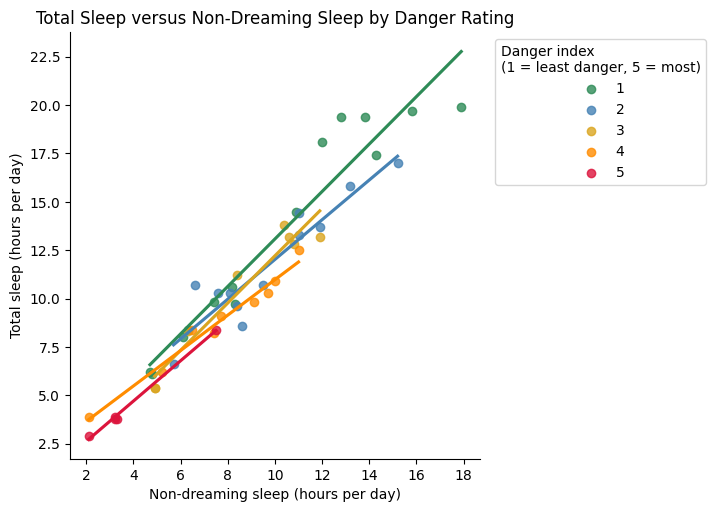

In [22]:
# Plot the non-dreaming–total sleep relationship by danger category.
rating_order = [1, 2, 3, 4, 5]
rating_palette = ["seagreen", "steelblue", "goldenrod", "darkorange", "crimson"]

sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="danger_index",
    hue_order=rating_order,
    palette=rating_palette,
    ci=None,
    legend=False
)
plt.title("Total Sleep versus Non-Dreaming Sleep by Danger Rating")
plt.xlabel("Non-dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.legend(title="Danger index\n(1 = least danger, 5 = most)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


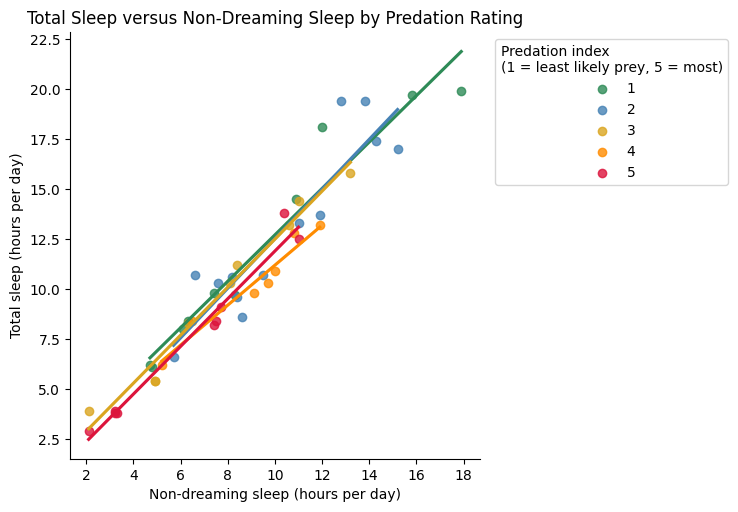

In [23]:
# Plot the non-dreaming–total sleep relationship by predation category.
sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="predation_index",
    hue_order=rating_order,
    palette=rating_palette,
    ci=None,
    legend=False
)
plt.title("Total Sleep versus Non-Dreaming Sleep by Predation Rating")
plt.xlabel("Non-dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.legend(title="Predation index\n(1 = least likely prey, 5 = most)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


**Describe overlap and separation in each plot. How do the group sizes and available non-dreaming-sleep ranges affect your interpretation?**

Your answer:

**Danger.** The five colors overlap along one rising band. The rating 1 line is the highest and the rating 5 points are at the lower left, but the groups differ more in where they sit along the horizontal axis than in how high they sit at the same non-dreaming sleep. Rating 5 has 5 species and none above 7.5 hours of non-dreaming sleep. Rating 1 has 14 species and reaches 17.9 hours.

**Predation.** The overlap is heavier. The lines lie close together through the middle of the plot, with the rating 4 line a little lower at its right end, and I cannot pick out a rating by its height.

The group sizes run from 5 to 14 for danger and from 7 to 13 for predation. A line fitted to 5 or 7 points can tilt a lot from one species, so I do not read much into differences in slope. The ranges also differ. Where a group has no species, its line is not showing data, so the fair comparison is only over the non-dreaming sleep values that two groups share.


### Compare model R-squared

The supplied helper follows the lecture's least-squares calculation. Read and run it; you do not need to recreate its matrix operations. `pd.get_dummies()` represents each rating with category indicators. `drop_first=True` chooses a reference level. This avoids assuming equal distances between index values.

These are **additive models**: one shared slope for the quantitative predictor and category-specific intercept adjustments. They differ from the separate group slopes in `lmplot()`. Compare the baseline, baseline plus danger, baseline plus predation, and baseline plus both, all on identical rows and the same response scale. Training R-squared cannot decrease when predictors are added to these nested models; an increase alone does not establish improved performance on new observations.

In [24]:
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features, drop_first=True, dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [25]:
# Build and display phase_comparison for the four models.
phase_comparison = pd.Series(
    {
        "Non-dreaming sleep only": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", []
        ),
        "Non-dreaming sleep + danger": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", ["danger_index"]
        ),
        "Non-dreaming sleep + predation": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", ["predation_index"]
        ),
        "Non-dreaming sleep + danger + predation": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", ["danger_index", "predation_index"]
        )
    },
    name="r_squared"
)

phase_comparison.round(3)


Non-dreaming sleep only                    0.927
Non-dreaming sleep + danger                0.943
Non-dreaming sleep + predation             0.937
Non-dreaming sleep + danger + predation    0.951
Name: r_squared, dtype: float64

In [26]:
# Show how much each model's R-squared changes from non-dreaming sleep alone.
phase_changes = pd.DataFrame({
    "r_squared": phase_comparison,
    "change_from_baseline": phase_comparison - phase_comparison["Non-dreaming sleep only"]
})
display(phase_changes.round(3))

print(f"Variation left by the baseline model: {(1 - phase_comparison['Non-dreaming sleep only']) * 100:.1f}%")
print(f"Variation left by the model with both indices: {(1 - phase_comparison['Non-dreaming sleep + danger + predation']) * 100:.1f}%")


,r_squared,change_from_baseline
Non-dreaming sleep only,0.927,0.000
Non-dreaming sleep + danger,0.943,0.016
Non-dreaming sleep + predation,0.937,0.010
Non-dreaming sleep + danger + predation,0.951,0.025


Variation left by the baseline model: 7.3%
Variation left by the model with both indices: 4.9%


In [27]:
# Total sleep minus non-dreaming sleep is dreaming sleep, so compare dreaming sleep across the ratings.
display(sleep_df.groupby("danger_index")["dreaming_sleep"].agg(["count", "mean"]).round(2))
display(sleep_df.groupby("predation_index")["dreaming_sleep"].agg(["count", "mean"]).round(2))


,count,mean
danger_index,,
1,14,3.14
2,12,2.02
3,8,1.89
4,9,1.18
5,5,0.70


,count,mean
predation_index,,
1,10,2.62
2,13,2.59
3,9,2.04
4,7,1.20
5,9,1.18


## Step 4: Check

For each danger rating, display the smallest and largest non-dreaming sleep values using `.groupby()` and `.agg(["min", "max"])`. Repeat for predation ratings.

Compare these ranges with the group plots. Use the ranges to identify where two groups actually have observations at similar non-dreaming sleep durations.

In [28]:
# Display the non-dreaming sleep range for each danger and predation rating.
display(sleep_df.groupby("danger_index")["non_dreaming_sleep"].agg(["min", "max"]))
display(sleep_df.groupby("predation_index")["non_dreaming_sleep"].agg(["min", "max"]))


,min,max
danger_index,,
1,4.7,17.9
2,5.7,15.2
3,4.9,11.9
4,2.1,11.0
5,2.1,7.5


,min,max
predation_index,,
1,4.7,17.9
2,5.7,15.2
3,2.1,13.2
4,5.2,11.9
5,2.1,11.0


In [29]:
# Count the danger 1 and danger 5 records inside the range of non-dreaming sleep that both groups cover.
danger_ranges = sleep_df.groupby("danger_index")["non_dreaming_sleep"].agg(["min", "max"])
shared_low = max(danger_ranges.loc[1, "min"], danger_ranges.loc[5, "min"])
shared_high = min(danger_ranges.loc[1, "max"], danger_ranges.loc[5, "max"])
print(f"Shared non-dreaming sleep range for danger 1 and danger 5: {shared_low} to {shared_high} hours per day")

in_shared_range = sleep_df.loc[
    sleep_df["danger_index"].isin([1, 5]) & sleep_df["non_dreaming_sleep"].between(shared_low, shared_high),
    ["species", "danger_index", "non_dreaming_sleep", "total_sleep"]
].sort_values(["danger_index", "non_dreaming_sleep"])
display(in_shared_range)
display(in_shared_range["danger_index"].value_counts().sort_index())


Shared non-dreaming sleep range for danger 1 and danger 5: 4.7 to 7.5 hours per day


,species,danger_index,non_dreaming_sleep,total_sleep
24,Gray seal,1,4.7,6.2
18,Genet,1,4.8,6.1
33,Man,1,6.1,8.0
14,Eastern American mole,1,6.3,8.4
48,Red fox,1,7.4,9.8
45,Rabbit,5,7.5,8.4


danger_index
1    5
5    1
Name: count, dtype: int64

**Choose two danger groups. Over what range of non-dreaming sleep do both groups have observations? Why should you compare their lines within that shared range?**

Your answer:

I chose danger ratings 1 and 5. Rating 1 covers 4.7 to 17.9 hours of non-dreaming sleep and rating 5 covers 2.1 to 7.5, so both groups have observations only from 4.7 to 7.5 hours per day.

Inside that shared range there are 5 species with rating 1 and only 1 with rating 5, the rabbit (7.5 hours of non-dreaming sleep, 8.4 hours of total sleep). The comparison between these two groups therefore rests on one high-danger species.

The lines should be compared inside the shared range because that is the only place where both groups have data at similar non-dreaming sleep. Above 7.5 hours there is no rating 5 species and below 4.7 hours there is no rating 1 species, so a difference between the lines out there would be a difference between a line and nothing.


## Step 5: Conclusion

**Research question:** Do danger and predation categories add information about total sleep beyond non-dreaming sleep?

**Does adding danger, predation, or both improve the model of total sleep? Report the four R-squared values and how much each changes from non-dreaming sleep alone. Are the improvements small or large? Explain how the group plots support your answer.**

Your answer:

Each addition raises R-squared, but only by a small amount.

| Model | R-squared | Change from non-dreaming sleep alone |
| --- | ---: | ---: |
| Non-dreaming sleep only | 0.927 | 0.000 |
| Non-dreaming sleep + danger | 0.943 | 0.016 |
| Non-dreaming sleep + predation | 0.937 | 0.010 |
| Non-dreaming sleep + danger + predation | 0.951 | 0.025 |

The changes are calculated from the unrounded R-squared values, so the last digit can differ by 0.001 from subtracting the rounded numbers in the table.

The baseline leaves 7.3% of the variation in total sleep unaccounted for, and the model with both indices leaves 4.9%. Danger adds a little more than predation, as I predicted, and both additions are small.

The group plots support this. The colors overlap along one band, and where two groups share the same non-dreaming sleep their points are close in height. Because total sleep is non-dreaming plus dreaming sleep, whatever the indices add beyond non-dreaming sleep has to be about dreaming sleep. Mean dreaming sleep does fall as danger rises, from 3.14 hours at rating 1 to 0.70 hours at rating 5, which is where the small gain comes from.

An increase in R-squared on the same 48 records does not show that the larger models would do better on new species. The combined model uses eight added category columns, and R-squared cannot go down when columns are added.


## Step 6: Limitation

**Identify two limitations of this investigation.**

Your answer:

1. The rating groups are small and uneven. Danger rating 5 has 5 species and the largest group has 14, and the groups cover different ranges of non-dreaming sleep. The comparison of ratings 1 and 5 came down to a single rabbit in the shared range.

2. Danger and predation mostly repeat each other. Thirty-four of the 48 species (70.8%) have the same rating on both, so the models cannot separate what each index adds. The ratings are also ordered judgments from the original study, not measurements, and the R-squared values describe fit to these 48 records only.


# Investigation 3: Gestation time and total sleep

## Step 1: Question

**How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?**

Gestation time is the length of a pregnancy, measured in days. We will compare it with total sleep, measured in hours per day, and see whether taking the logarithm of gestation time makes the pattern look straighter.

**Do you expect mammals with longer pregnancies to sleep more hours per day, fewer hours, or about the same amount? Explain your initial guess. You do not need prior knowledge about mammals; you will compare your prediction with the data.**

Your answer:

My guess is that mammals with longer pregnancies sleep fewer hours per day. I am thinking of large animals. The horse had the least total sleep in the first investigation (2.9 hours), and large grazing animals have long pregnancies, while small animals like bats and opossums were at the top for sleep. I do not know if the pattern holds across all the species, so I expect a negative relationship with a lot of scatter.


## Step 2: Data

Create `gestation_df` by dropping rows missing `gestation_time`, `total_sleep`, `danger_index`, or `predation_index`, then copying the result. How many records were removed from the dataset? Do not drop rows merely because maximum lifespan is missing. Check that gestation is positive and sleep is between 0 and 24 hours per day. Create `log10_gestation_time` only after checking the inputs.

In [30]:
# Prepare gestation_df and check counts and plausible ranges.
gestation_features = ["gestation_time", "total_sleep", "danger_index", "predation_index"]
gestation_df = mammals_df.dropna(subset=gestation_features).copy()

print("Records in mammals_df:", len(mammals_df))
print("Records in gestation_df:", len(gestation_df))
print("Records removed:", len(mammals_df) - len(gestation_df))

display(gestation_df[["gestation_time", "total_sleep"]].agg(["min", "max"]))
print("All gestation times are positive:", (gestation_df["gestation_time"] > 0).all())
print("All total sleep values are between 0 and 24 hours per day:", gestation_df["total_sleep"].between(0, 24).all())

# The inputs are positive, so the logarithm is defined for every record.
gestation_df["log10_gestation_time"] = np.log10(gestation_df["gestation_time"])


Records in mammals_df: 62
Records in gestation_df: 54
Records removed: 8


,gestation_time,total_sleep
min,12.0,2.6
max,645.0,19.9


All gestation times are positive: True
All total sleep values are between 0 and 24 hours per day: True


In [31]:
# Display the removed records to see which measurement each one is missing.
removed_from_gestation = mammals_df.loc[
    ~mammals_df.index.isin(gestation_df.index),
    ["species", "gestation_time", "total_sleep", "max_life_span"]
]
print("Removed for missing gestation time:", removed_from_gestation["gestation_time"].isnull().sum())
print("Removed for missing total sleep:", removed_from_gestation["total_sleep"].isnull().sum())
display(removed_from_gestation)

print("Records kept in gestation_df even though maximum lifespan is missing:", gestation_df["max_life_span"].isnull().sum())


Removed for missing gestation time: 4
Removed for missing total sleep: 4


,species,gestation_time,total_sleep,max_life_span
12,Desert hedgehog,NaN,10.3,NaN
18,Genet,NaN,6.1,34.0
19,Giant armadillo,NaN,18.1,7.0
20,Giraffe,400.0,NaN,28.0
30,Kangaroo,33.0,NaN,16.3
40,Okapi,440.0,NaN,23.6
55,Star nosed mole,NaN,10.3,3.5
61,Yellow-bellied marmot,38.0,NaN,13.0


Records kept in gestation_df even though maximum lifespan is missing: 3


## Step 3: Evidence

Plot sleep against gestation on original scales, then against log10 gestation, leaving sleep in hours per day. Calculate correlation and simple-line R-squared for each. These R-squared values share the same response scale and observations. Compare whether the points follow a straight or curved pattern and how widely they are scattered, as well as the numerical summaries.

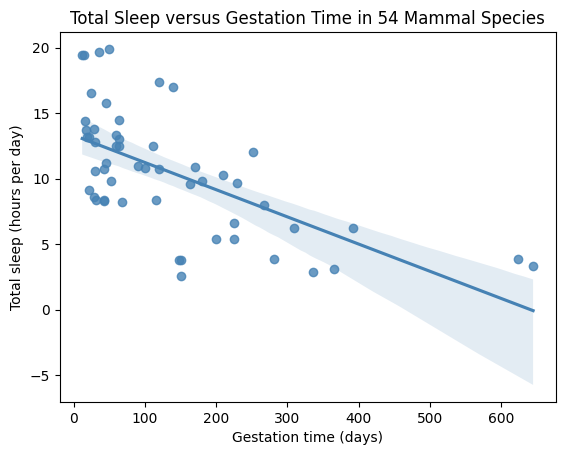

In [32]:
# Plot original gestation and sleep.
sns.regplot(
    data=gestation_df,
    x="gestation_time",
    y="total_sleep",
    color="steelblue"
)
plt.title("Total Sleep versus Gestation Time in 54 Mammal Species")
plt.xlabel("Gestation time (days)")
plt.ylabel("Total sleep (hours per day)")
plt.show()


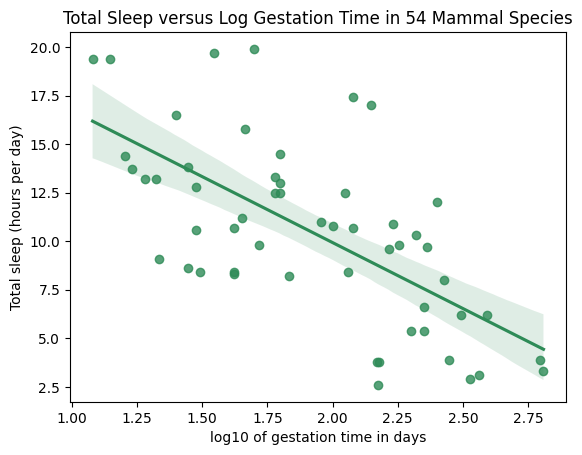

In [33]:
# Plot log gestation and sleep.
sns.regplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    color="seagreen"
)
plt.title("Total Sleep versus Log Gestation Time in 54 Mammal Species")
plt.xlabel("log10 of gestation time in days")
plt.ylabel("Total sleep (hours per day)")
plt.show()


In [34]:
# Calculate the two correlations and squared correlations.
gestation_r = gestation_df["gestation_time"].corr(gestation_df["total_sleep"])
log_gestation_r = gestation_df["log10_gestation_time"].corr(gestation_df["total_sleep"])

gestation_summary = pd.DataFrame(
    {
        "correlation": [gestation_r, log_gestation_r],
        "r_squared": [gestation_r ** 2, log_gestation_r ** 2]
    },
    index=["Gestation time (days)", "log10 gestation time"]
)
display(gestation_summary.round(3))

print(f"Change in R-squared from the log transformation: {log_gestation_r ** 2 - gestation_r ** 2:.3f}")
print(f"Variation in total sleep left by the log-gestation line: {(1 - log_gestation_r ** 2) * 100:.1f}%")


,correlation,r_squared
Gestation time (days),-0.631,0.399
log10 gestation time,-0.664,0.440


Change in R-squared from the log transformation: 0.042
Variation in total sleep left by the log-gestation line: 56.0%


In [35]:
# Read the original-scale line's fitted total sleep at the shortest and longest gestation times.
slope, intercept = np.polyfit(gestation_df["gestation_time"], gestation_df["total_sleep"], 1)
for days in [gestation_df["gestation_time"].min(), gestation_df["gestation_time"].max()]:
    print(f"Fitted total sleep at {days:.0f} days: {intercept + slope * days:.1f} hours per day")


Fitted total sleep at 12 days: 13.1 hours per day
Fitted total sleep at 645 days: -0.1 hours per day


In [36]:
# Count how the gestation times are spread across the original scale.
print("Species with gestation of 100 days or less:", (gestation_df["gestation_time"] <= 100).sum(), "of", len(gestation_df))
print("Species with gestation above 300 days:", (gestation_df["gestation_time"] > 300).sum(), "of", len(gestation_df))
print("Median gestation time:", gestation_df["gestation_time"].median(), "days")


Species with gestation of 100 days or less: 29 of 54
Species with gestation above 300 days: 6 of 54
Median gestation time: 79.0 days


**What changes when gestation is log-transformed? Does the transformation remove the scatter or only improve the straight-line summary modestly?**

Your answer:

On the original scale most species are crowded at the left side of the plot. Twenty-nine of the 54 have a gestation of 100 days or less and only 6 are above 300 days. The highest sleep values are at short gestations, and the points bend away from the line. At the longest gestation, 645 days, the line gives -0.1 hours of sleep per day, which is impossible.

With log10 gestation the species are spread across the whole horizontal axis and the pattern looks closer to straight. The correlation moves from -0.631 to -0.664 and R-squared from 0.399 to 0.440, a gain of 0.042 before rounding.

The transformation does not remove the scatter. It improves the straight-line summary modestly, and 56.0% of the variation in total sleep is still not accounted for by the log-gestation line.


Reuse the group-plot and model-comparison approach from Investigation 2, now using `log10_gestation_time` as the predictor and `total_sleep` as the response. Count observations at each rating level in this subset before interpreting the group lines. Examine danger and predation separately, then compare all four additive models on `gestation_df`.

In [37]:
# Count ratings in the sleep subset.
gestation_rating_counts = pd.DataFrame({
    "danger_index": gestation_df["danger_index"].value_counts().sort_index(),
    "predation_index": gestation_df["predation_index"].value_counts().sort_index()
})
gestation_rating_counts.index.name = "rating"
gestation_rating_counts


,danger_index,predation_index
rating,,
1,16,12
2,12,14
3,10,9
4,9,7
5,7,12


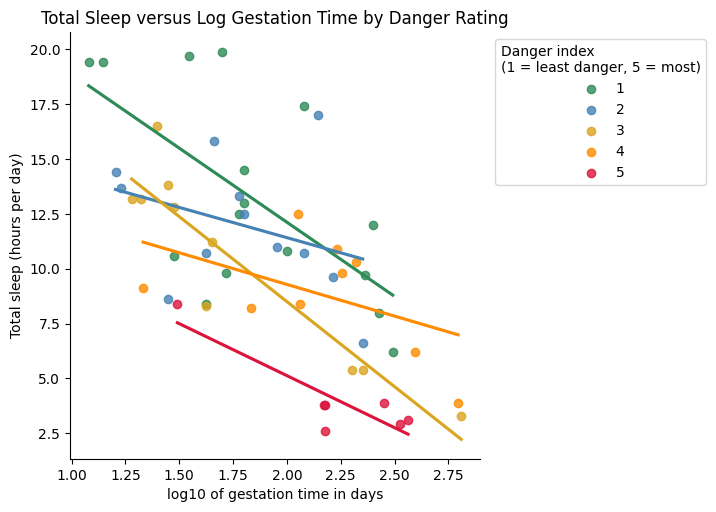

In [38]:
# Plot log gestation and sleep by danger.
sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="danger_index",
    hue_order=rating_order,
    palette=rating_palette,
    ci=None,
    legend=False
)
plt.title("Total Sleep versus Log Gestation Time by Danger Rating")
plt.xlabel("log10 of gestation time in days")
plt.ylabel("Total sleep (hours per day)")
plt.legend(title="Danger index\n(1 = least danger, 5 = most)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


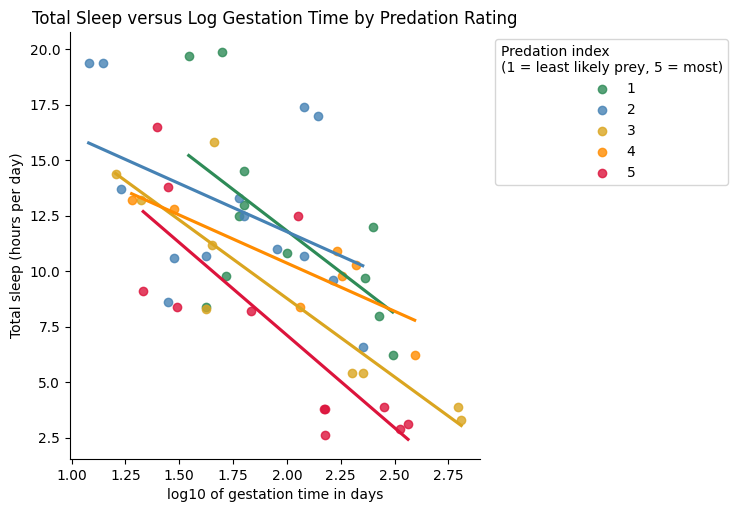

In [39]:
# Plot log gestation and sleep by predation.
sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="predation_index",
    hue_order=rating_order,
    palette=rating_palette,
    ci=None,
    legend=False
)
plt.title("Total Sleep versus Log Gestation Time by Predation Rating")
plt.xlabel("log10 of gestation time in days")
plt.ylabel("Total sleep (hours per day)")
plt.legend(title="Predation index\n(1 = least likely prey, 5 = most)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


In [40]:
# Build and display sleep_comparison for the four models.
sleep_comparison = pd.Series(
    {
        "Log gestation only": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", []
        ),
        "Log gestation + danger": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", ["danger_index"]
        ),
        "Log gestation + predation": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", ["predation_index"]
        ),
        "Log gestation + danger + predation": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", ["danger_index", "predation_index"]
        )
    },
    name="r_squared"
)

sleep_comparison.round(3)


Log gestation only                    0.440
Log gestation + danger                0.654
Log gestation + predation             0.592
Log gestation + danger + predation    0.694
Name: r_squared, dtype: float64

In [41]:
# Show how much each model's R-squared changes from log gestation alone.
sleep_changes = pd.DataFrame({
    "r_squared": sleep_comparison,
    "change_from_baseline": sleep_comparison - sleep_comparison["Log gestation only"]
})
display(sleep_changes.round(3))


,r_squared,change_from_baseline
Log gestation only,0.440,0.000
Log gestation + danger,0.654,0.214
Log gestation + predation,0.592,0.151
Log gestation + danger + predation,0.694,0.254


In [42]:
# Compare average total sleep and gestation across the danger ratings.
gestation_df.groupby("danger_index")[["total_sleep", "gestation_time"]].agg(["count", "mean"]).round(1)


total_sleep       gestation_time       
                   count  mean          count   mean
danger_index                                        
1                     16  13.2             16  106.2
2                     12  12.0             12   84.2
3                     10  10.3             10  128.0
4                      9   8.8              9  210.3
5                      7   4.1              7  208.9

## Step 4: Check

For the first five records, display gestation time, its logarithm, and `10 ** log10_gestation_time`. Does reversing the logarithm recover the original number of days?

Display the records with the shortest and longest gestation times. Find their points in both plots and compare the recorded sleep hours with their vertical positions. The horizontal positions change when gestation is transformed; the sleep measurements stay the same.

In [43]:
# Reverse the logarithm for five records and compare with the original gestation times.
log_check = gestation_df[["species", "gestation_time", "log10_gestation_time"]].head().copy()
log_check["reversed_gestation_time"] = 10 ** log_check["log10_gestation_time"]
log_check["matches_original"] = np.isclose(log_check["reversed_gestation_time"], log_check["gestation_time"])
log_check


,species,gestation_time,log10_gestation_time,reversed_gestation_time,matches_original
0,African elephant,645.0,2.809560,645.0,True
1,African giant pouched rat,42.0,1.623249,42.0,True
2,Arctic Fox,60.0,1.778151,60.0,True
3,Arctic ground squirrel,25.0,1.397940,25.0,True
4,Asian elephant,624.0,2.795185,624.0,True


In [44]:
# Inspect extreme gestation records.
extreme_cols = ["species", "gestation_time", "log10_gestation_time", "total_sleep"]

print("Shortest gestation time:")
display(gestation_df.nsmallest(1, "gestation_time")[extreme_cols].round(3))

print("Longest gestation time:")
display(gestation_df.nlargest(1, "gestation_time")[extreme_cols].round(3))


Shortest gestation time:


,species,gestation_time,log10_gestation_time,total_sleep
38,N. American opossum,12.0,1.079,19.4


Longest gestation time:


,species,gestation_time,log10_gestation_time,total_sleep
0,African elephant,645.0,2.81,3.3


**Did reversing the logarithm recover the original gestation times? For the shortest and longest gestation records, do both plots show the recorded total sleep values? Describe what changed between the plots and what stayed the same.**

Your answer:

Yes. For all five records, 10 raised to the log value returns the original number of days. The African elephant's 645.0 days becomes 2.809560 and reverses to 645.0.

The shortest gestation is the North American opossum at 12 days with 19.4 hours of total sleep, and the longest is the African elephant at 645 days with 3.3 hours. Both plots show those sleep values. The opossum is at the far left near the top at 19.4, and the elephant is the point at the far right near the bottom at 3.3.

What changed is the horizontal position. The opossum moves from 12 on the days axis to 1.079 on the log axis, and the elephant from 645 to 2.81, which pulls the long gestations in toward the rest of the species. The vertical positions stayed the same because total sleep was not transformed.


## Step 5: Conclusion

**Research question:** How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?

**Do mammals with longer gestation times tend to sleep more or less? Does using log gestation make the pattern look straighter? Do danger and predation add information? Support your answers with the plots, correlation, and R-squared values, and compare the results with your prediction.**

Your answer:

Mammals with longer gestation times tend to sleep less. The correlation between gestation time and total sleep is -0.631 on the original scale and -0.664 with log10 gestation. Using log gestation makes the pattern look straighter and raises R-squared from 0.399 to 0.440, but the points are still widely scattered around the line.

Danger and predation add much more here than they did in Investigation 2.

| Model | R-squared | Change from log gestation alone |
| --- | ---: | ---: |
| Log gestation only | 0.440 | 0.000 |
| Log gestation + danger | 0.654 | 0.214 |
| Log gestation + predation | 0.592 | 0.151 |
| Log gestation + danger + predation | 0.694 | 0.254 |

As in Investigation 2, the changes are calculated from the unrounded values.

The danger plot supports this. The rating 1 line is the highest through most of the plot and the rating 5 points are at the bottom, and mean total sleep falls from 13.2 hours at rating 1 to 4.1 hours at rating 5. The predation plot shows the same order less cleanly.

The result matches my prediction that longer pregnancies go with less sleep. These are fits to the same 54 species, so the larger R-squared values describe these records and do not show that danger causes less sleep or that the models would do as well on other species.


## Step 6: Limitation

**Identify two limitations of the gestation and sleep investigation.**

Your answer:

1. Gestation, danger, and sleep are tangled together. Species with danger ratings 4 and 5 average 210.3 and 208.9 days of gestation, against 106.2 days for rating 1, so the models cannot separate a gestation pattern from a danger pattern. Body size is likely related to all three and is not in these models. Nothing here shows cause.

2. The sample is small for the number of groups. There are 54 species after 8 were removed for a missing gestation time or total sleep, the danger groups hold 7 to 16 species, and the combined model adds eight category columns. R-squared on the same records cannot go down when columns are added, and even the log line leaves 56.0% of the variation in total sleep unaccounted for.


## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:

Yes. I used an AI assistant (Claude) to help write the code and to draft the written answers, and I checked the answers against the notebook output.

One suggestion I checked and modified: for the Step 4 question in Investigation 2, the draft compared danger ratings 1 and 5 by their lines. I checked that against the minimum and maximum table, which gives a shared range of 4.7 to 7.5 hours of non-dreaming sleep, and then counted the records inside that range. There were 5 species with rating 1 and only 1 with rating 5, the rabbit. I kept the two groups but changed the answer to say that the comparison rests on one species, and I kept the count cell in the notebook so the claim can be checked.


## Submission checklist

- Use the supplied CSV with a relative path.
- Complete the dictionary table and every written response.
- Include a prediction and all six workflow steps for each investigation.
- Include all three sleep comparison plots, two non-dreaming–total group plots, original and log-gestation sleep plots, and two sleep group plots.
- Keep observations consistent within each comparison; report counts and investigate exclusions.
- Interpret correlation and R-squared on the correct scale, using numerical and visual evidence.
- Compare baseline, danger, predation, and combined models without claiming automatic causal or predictive improvement.
- Explain whether the patterns are straight or curved, how the log transformation changes the gestation plot, and what the analyses cannot tell us.
- Complete the AI-use reflection, restart the kernel, and run the notebook in order before submitting.